In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc file dữ liệu đã tải lên
df = pd.read_csv('merged_data.csv', sep=';')

# Xem số dòng, số cột
print("Số dòng và số cột của tập dữ liệu:", df.shape)

# Xem thử 5 dòng đầu tiên
df.head(5)

Số dòng và số cột của tập dữ liệu: (6758, 15)


,source,product_id,product_name,brand,category,volume_weight,volume_val,volume_unit,current_price,original_price,discount_percent,rating,review_count,has_rating,product_url
0,Hasaki,102959,Sữa Rửa Mặt CeraVe Sạch Sâu Cho Da Thường Đến ...,CeraVe,Chăm sóc da,473ml,473.0,ml,360000,490000,26.5,4.9,116,1,https://hasaki.vn/san-pham/sua-rua-mat-cerave-...
1,Hasaki,96589,Combo 2 Nước Tẩy Trang Bí Đao Cocoon Làm Sạch ...,Cocoon,Chăm sóc da,500ml,500.0,ml,295000,590000,50.0,5.0,57,1,https://hasaki.vn/san-pham/combo-2-nuoc-tay-tr...
2,Hasaki,124096,Combo Cocoon Nước Cân Bằng Sen Hậu Giang 310ml...,Cocoon,Chăm sóc da,310ml,310.0,ml,268000,590000,54.6,4.9,13,1,https://hasaki.vn/san-pham/combo-cocoon-nuoc-c...
3,Hasaki,65994,Nước Hoa Hồng Klairs Không Mùi Cho Da Nhạy Cảm...,Klairs,Chăm sóc da,180ml,180.0,ml,203000,435000,53.3,4.8,148,1,https://hasaki.vn/san-pham/nuoc-hoa-hong-khong...
4,Hasaki,9740,Nước Tẩy Trang Bioderma Dành Cho Da Nhạy Cảm 5...,Bioderma,Chăm sóc da,500ml,500.0,ml,360000,560000,35.7,4.9,228,1,https://hasaki.vn/san-pham/nuoc-tay-trang-biod...


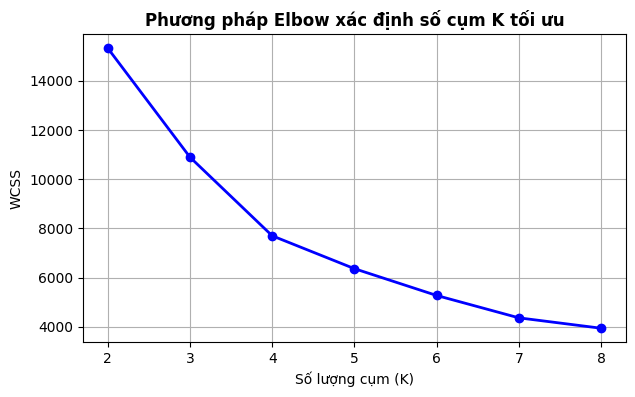

Điểm Silhouette Score: 0.391

--- BẢNG ĐẶC TRƯNG TỪNG CỤM ---


,So_luong,Gia_TB,Giam_Gia_TB,Review_TB
Cluster,,,,
0,2273,141891.3,53.1,4.9
1,3798,155836.6,18.4,3.8
2,93,233462.4,36.8,216.3
3,594,609546.6,26.2,6.6


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Chọn thuộc tính phân cụm
cluster_features = ['current_price', 'discount_percent', 'review_count']
df_cluster = df[cluster_features].copy()
df_cluster['review_count'] = df_cluster['review_count'].fillna(0)
df_cluster = df_cluster.dropna()

# 2. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

# 3. Vẽ biểu đồ Elbow xác định số cụm K
wcss = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 9), wcss, 'bo-', linewidth=2)
plt.title('Phương pháp Elbow xác định số cụm K tối ưu', fontweight='bold')
plt.xlabel('Số lượng cụm (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

# 4. Huấn luyện mô hình với K = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_cluster['Cluster'] = kmeans.fit_predict(X_scaled)

print("Điểm Silhouette Score:", round(silhouette_score(X_scaled, df_cluster['Cluster']), 3))

# 5. Xem đặc trưng từng cụm sản phẩm
print("\n--- BẢNG ĐẶC TRƯNG TỪNG CỤM ---")
display(df_cluster.groupby('Cluster').agg(
    So_luong=('current_price', 'count'),
    Gia_TB=('current_price', 'mean'),
    Giam_Gia_TB=('discount_percent', 'mean'),
    Review_TB=('review_count', 'mean')
).round(1))

           KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH HỒI QUY
Hệ số xác định (R² Score)       : 0.2662
Sai số tuyệt đối TB (MAE)       : 91,996 VNĐ
Căn bậc hai sai số TB (RMSE)    : 145,353 VNĐ
-------------------------------------------------------
Sai số MAE của Mô hình cơ sở (Baseline Dummy) : 121,706 VNĐ
Sai số RMSE của Mô hình cơ sở (Baseline Dummy): 169,805 VNĐ


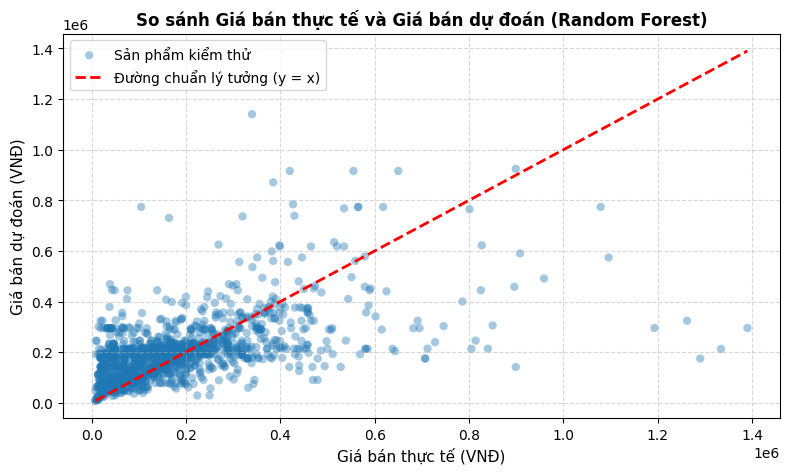

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

# 1. Chuẩn bị tập dữ liệu
# Lưu ý: Tuyệt đối không dùng original_price và discount_percent để tránh rò rỉ dữ liệu
features_reg = ['source', 'category', 'brand', 'rating', 'review_count', 'current_price']
df_reg = df[features_reg].copy().dropna(subset=['current_price'])

# Chuyển đổi các cột số
df_reg['current_price'] = pd.to_numeric(df_reg['current_price'], errors='coerce')
df_reg['rating'] = pd.to_numeric(df_reg['rating'], errors='coerce')
df_reg['review_count'] = pd.to_numeric(df_reg['review_count'], errors='coerce')

# Gom nhóm các thương hiệu xuất hiện ít (dưới 15 sản phẩm) thành 'Other' để mô hình tối ưu
brand_counts = df_reg['brand'].value_counts()
top_brands = brand_counts[brand_counts >= 15].index
df_reg['brand_clean'] = df_reg['brand'].apply(lambda x: x if x in top_brands else 'Other')

# Tách biến đặc trưng (X) và biến mục tiêu dự đoán (y)
X = df_reg[['source', 'category', 'brand_clean', 'rating', 'review_count']]
y = df_reg['current_price']

# Chia dữ liệu theo tỷ lệ 80% Train - 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Xây dựng Pipeline tiền xử lý
numerical_cols = ['rating', 'review_count']
categorical_cols = ['source', 'category', 'brand_clean']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, numerical_cols),
    ('cat', cat_pipeline, categorical_cols)
])

# 3. Huấn luyện mô hình Random Forest Regressor
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

rf_pipeline.fit(X_train, y_train)
y_pred = rf_pipeline.predict(X_test)

# 4. Huấn luyện mô hình cơ sở (Dummy Regressor - dự đoán bằng giá trị trung bình) để đối chứng
dummy_model = DummyRegressor(strategy='mean')
dummy_model.fit(X_train, y_train)
y_dummy_pred = dummy_model.predict(X_test)

# 5. Đánh giá chất lượng mô hình
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

dummy_mae = mean_absolute_error(y_test, y_dummy_pred)
dummy_rmse = np.sqrt(mean_squared_error(y_test, y_dummy_pred))

print("="*55)
print("           KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH HỒI QUY")
print("="*55)
print(f"Hệ số xác định (R² Score)       : {r2:.4f}")
print(f"Sai số tuyệt đối TB (MAE)       : {mae:,.0f} VNĐ")
print(f"Căn bậc hai sai số TB (RMSE)    : {rmse:,.0f} VNĐ")
print("-"*55)
print(f"Sai số MAE của Mô hình cơ sở (Baseline Dummy) : {dummy_mae:,.0f} VNĐ")
print(f"Sai số RMSE của Mô hình cơ sở (Baseline Dummy): {dummy_rmse:,.0f} VNĐ")
print("="*55)

# 6. Vẽ biểu đồ Giá thực tế vs Giá dự đoán
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.4, color='#1f77b4', edgecolors='none', label='Sản phẩm kiểm thử')
# Đường chuẩn 45 độ (y = x)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Đường chuẩn lý tưởng (y = x)')

plt.title('So sánh Giá bán thực tế và Giá bán dự đoán (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Giá bán thực tế (VNĐ)', fontsize=11)
plt.ylabel('Giá bán dự đoán (VNĐ)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

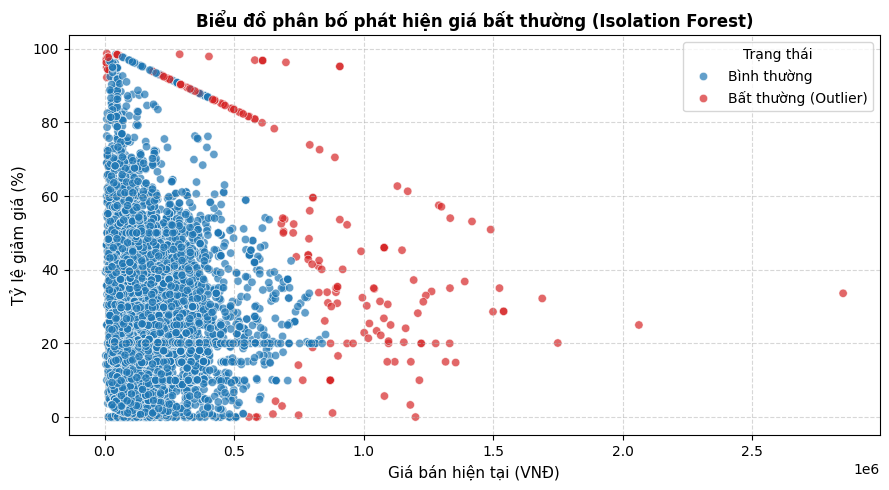

Tổng số sản phẩm phân tích: 6758
Số sản phẩm phát hiện bất thường: 202 (2.99%)

--- TOP 5 SẢN PHẨM BẤT THƯỜNG TIÊU BIỂU ---


,source,product_name,current_price,original_price,discount_percent
19,Hasaki,Serum La Roche-Posay Giảm Thâm Nám & Dưỡng Sán...,899000,1390000,35.3
34,Hasaki,"Kem Dưỡng Vichy Sáng Da, Mờ Thâm Nám Ban Đêm 50ml",898000,1300000,30.9
46,Hasaki,Serum La Roche-Posay Giúp Làm Mịn & Dưỡng Ẩm D...,1041000,1597000,34.8
67,Hasaki,"Kem Dưỡng Vichy Giảm Dấu Hiệu Lão Hóa, Săn Chắ...",859000,1300000,33.9
75,Hasaki,1.0 Soothing Retinol,1390000,2200000,36.8


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

# 1. Chuẩn bị dữ liệu định giá
iso_cols = ['product_name', 'source', 'brand', 'current_price', 'original_price', 'discount_percent']
iso_df = df[iso_cols].dropna().copy()

# Chuyển đổi kiểu dữ liệu số
iso_df['current_price'] = pd.to_numeric(iso_df['current_price'], errors='coerce')
iso_df['discount_percent'] = pd.to_numeric(iso_df['discount_percent'], errors='coerce')
iso_df = iso_df[(iso_df['current_price'] > 0) & (iso_df['discount_percent'] >= 0)]

# 2. Huấn luyện mô hình Isolation Forest
# Tham số contamination=0.03 (ước lượng khoảng 3% sản phẩm có chiến lược giá/khuyến mãi bất thường)
features_anomaly = ['current_price', 'discount_percent']
iso_model = IsolationForest(n_estimators=100, contamination=0.03, random_state=42)

iso_df['is_outlier'] = iso_model.fit_predict(iso_df[features_anomaly])
iso_df['Trang_thai'] = iso_df['is_outlier'].map({1: 'Bình thường', -1: 'Bất thường (Outlier)'})

# 3. Vẽ biểu đồ phân bố phát hiện giá bất thường
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=iso_df,
    x='current_price',
    y='discount_percent',
    hue='Trang_thai',
    palette={'Bình thường': '#1f77b4', 'Bất thường (Outlier)': '#d62728'},
    alpha=0.7
)
plt.title('Biểu đồ phân bố phát hiện giá bất thường (Isolation Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Giá bán hiện tại (VNĐ)', fontsize=11)
plt.ylabel('Tỷ lệ giảm giá (%)', fontsize=11)
plt.legend(title='Trạng thái')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 4. Thống kê kết quả
outliers = iso_df[iso_df['is_outlier'] == -1]
print(f"Tổng số sản phẩm phân tích: {len(iso_df)}")
print(f"Số sản phẩm phát hiện bất thường: {len(outliers)} ({len(outliers)/len(iso_df)*100:.2f}%)")
print("\n--- TOP 5 SẢN PHẨM BẤT THƯỜNG TIÊU BIỂU ---")
display(outliers[['source', 'product_name', 'current_price', 'original_price', 'discount_percent']].head(5))